# XD CLAN — QAOA for Constrained Portfolio Optimization


## Live Portfolio Optimizer

**Deployed app:** [https://qiskit-fall-fest-2026-iiitd-ajiq5qdibj2ujasptcycxm.streamlit.app/](https://qiskit-fall-fest-2026-iiitd-ajiq5qdibj2ujasptcycxm.streamlit.app/)

This is the project’s interactive portfolio optimizer deployment. The notebook remains reproducible locally; the web app is a separate deployed interface.


## Project objective


## Notebook contents


## Method and interpretation


## Prerequisites
Run in a Python/Jupyter environment with Qiskit, Qiskit Algorithms, NumPy, pandas, SciPy, and Matplotlib. The installation cell below installs the core packages. The saved hardware run is documented separately below; rerunning the hardware job requires IBM Quantum Runtime account configuration.


In [ ]:
%pip install -q "qiskit>=1.2,<3" "qiskit-algorithms>=0.3" scipy matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.6 MB/s eta 0:00:00


In [ ]:
import itertools
import json
import math
import os
import sys
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import qiskit
import qiskit_algorithms
from IPython.display import display
from scipy.optimize import minimize
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorSampler

SEED = 2026
np.set_printoptions(precision=6, suppress=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit Algorithms:", qiskit_algorithms.__version__)
print("Setup complete.")


Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Qiskit: 2.5.2
Qiskit Algorithms: 0.4.0
Setup complete.


In [ ]:
rng = np.random.default_rng(SEED)

n, K, q = 6, 3, 0.5
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

def portfolio_cost(x, lam=1.0):
    x = np.asarray(x, dtype=float)
    return float(q * (x @ sigma @ x) - mu @ x + lam * (x.sum() - K) ** 2)

states = np.array(list(itertools.product([0, 1], repeat=n)), dtype=int)
feasible = states[states.sum(axis=1) == K]
feasible_costs = np.array([portfolio_cost(x, lam=0.0) for x in feasible])

best_idx = int(np.argmin(feasible_costs))
best_portfolio = feasible[best_idx]
best_cost = float(feasible_costs[best_idx])

assert len(states) == 64
assert len(feasible) == math.comb(n, K) == 20
assert np.allclose(sigma, sigma.T)
assert np.linalg.eigvalsh(sigma).min() >= -1e-10

print("All configurations:", len(states))
print("Feasible portfolios:", len(feasible))
print("Expected returns:", mu)
print("Best stocks (1-based):", (np.where(best_portfolio == 1)[0] + 1).tolist())
print("Best feasible cost:", round(best_cost, 8))
print("CLASSICAL BENCHMARK VERIFIED")

All configurations: 64
Feasible portfolios: 20
Expected returns: [0.085787 0.177983 0.143454 0.1241   0.120983 0.208104]
Best stocks (1-based): [2, 3, 6]
Best feasible cost: -0.50301469
CLASSICAL BENCHMARK VERIFIED


In [ ]:
from qiskit.quantum_info import Operator

LAMBDA = 1.0
basis_costs = np.zeros(2**n)

for index in range(2**n):
    x = np.array([(index >> i) & 1 for i in range(n)], dtype=int)
    basis_costs[index] = portfolio_cost(x, lam=LAMBDA)

hamiltonian = SparsePauliOp.from_operator(
    Operator(np.diag(basis_costs))
).simplify(atol=1e-12)

for index in range(2**n):
    actual = float(np.real(
        Statevector.from_int(index, dims=2**n).expectation_value(hamiltonian)
    ))
    assert np.isclose(actual, basis_costs[index], atol=1e-8), (index, actual, basis_costs[index])

print("Hamiltonian qubits:", hamiltonian.num_qubits)
print("Hamiltonian terms:", len(hamiltonian))
print("All 64 states validated successfully.")

Hamiltonian qubits: 6
Hamiltonian terms: 22
All 64 states validated successfully.


In [ ]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorSampler
from scipy.optimize import minimize

P = 1
ansatz = QAOAAnsatz(cost_operator=hamiltonian, reps=P, flatten=True)
ansatz.measure_all()

sampler = StatevectorSampler(seed=SEED, default_shots=4096)

def evaluate_qaoa(params):
    bound_circuit = ansatz.assign_parameters(params)
    result = sampler.run([bound_circuit], shots=4096).result()
    counts = result[0].data.meas.get_counts()
    total_cost = 0.0
    total_shots = sum(counts.values())

    for bitstring, count in counts.items():
        x = np.array([int(bit) for bit in bitstring[::-1]], dtype=int)
        total_cost += portfolio_cost(x, lam=LAMBDA) * count

    return total_cost / total_shots

initial_params = np.random.default_rng(SEED).uniform(0, 2 * np.pi, 2 * P)

optimization = minimize(
    evaluate_qaoa,
    initial_params,
    method="COBYLA",
    options={"maxiter": 60, "rhobeg": 1.0}
)

print("QAOA depth:", P)
print("Optimization successful:", optimization.success)
print("Function evaluations:", optimization.nfev)
print("Best sampled expectation:", round(float(optimization.fun), 8))
print("Optimized parameters:", optimization.x)

QAOA depth: 1
Optimization successful: True
Function evaluations: 31
Best sampled expectation: 0.31189652
Optimized parameters: [4.941004 3.490886]


In [ ]:
evaluation_rows = []
qaoa_depth_rows = []

for p in range(1, 5):
    ansatz = QAOAAnsatz(cost_operator=hamiltonian, reps=p, flatten=True)
    ansatz.measure_all()
    sampler = StatevectorSampler(seed=SEED + 500 + p, default_shots=4096)

    def objective(params):
        circuit = ansatz.assign_parameters(params)
        counts = sampler.run([circuit], shots=4096).result()[0].data.meas.get_counts()
        total = sum(counts.values())
        return sum(
            portfolio_cost(np.array([int(b) for b in bits[::-1]], dtype=int), lam=LAMBDA) * count
            for bits, count in counts.items()
        ) / total

    best_result = None
    for restart in range(3):
        initial_params = np.random.default_rng(SEED + 100 * p + restart).uniform(0, 2 * np.pi, 2 * p)
        result = minimize(
            objective,
            initial_params,
            method="COBYLA",
            options={"maxiter": 150, "rhobeg": 0.5, "tol": 1e-4}
        )
        if best_result is None or result.fun < best_result.fun:
            best_result = result

    qaoa_depth_rows.append({
        "p": p,
        "expectation": float(best_result.fun),
        "evaluations": int(best_result.nfev),
        "success": bool(best_result.success),
        "optimized_parameters": best_result.x.tolist()
    })

    counts = sampler.run(
        [ansatz.assign_parameters(best_result.x)],
        shots=4096
    ).result()[0].data.meas.get_counts()

    total_shots = sum(counts.values())
    feasible_shots = 0
    best_hits = 0
    sampled_costs = []

    for bits, count in counts.items():
        x = np.array([int(b) for b in bits[::-1]], dtype=int)
        cost = portfolio_cost(x, lam=0.0)
        if x.sum() == K:
            feasible_shots += count
            sampled_costs.append(cost)
            if np.array_equal(x, best_portfolio):
                best_hits += count

    evaluation_rows.append({
        "p": p,
        "shots": total_shots,
        "feasible_shots": feasible_shots,
        "feasible_rate_pct": 100 * feasible_shots / total_shots,
        "best_portfolio_hits": best_hits,
        "best_hit_rate_pct": 100 * best_hits / total_shots,
        "best_sampled_feasible_cost": min(sampled_costs, default=np.nan)
    })

qaoa_results_df = pd.DataFrame(qaoa_depth_rows)
evaluation_df = pd.DataFrame(evaluation_rows)
display(qaoa_results_df.drop(columns=["optimized_parameters"]))
display(evaluation_df)


,p,expectation,evaluations,success
0,1,0.193799,36,True
1,2,-0.298834,51,True
2,3,0.105382,65,True
3,4,0.333204,76,True


,p,shots,feasible_shots,feasible_rate_pct,best_portfolio_hits,best_hit_rate_pct,best_sampled_feasible_cost
0,1,4096,2564,62.597656,116,2.832031,-0.503015
1,2,4096,3927,95.874023,183,4.467773,-0.503015
2,3,4096,2985,72.875977,119,2.905273,-0.503015
3,4,4096,2282,55.712891,76,1.855469,-0.503015


,p,expectation,approximation_ratio,evaluations,success
0,1,0.193799,0.926674,36,True
1,2,-0.298834,0.978514,51,True
2,3,0.105382,0.935979,65,True
3,4,0.333204,0.912005,76,True


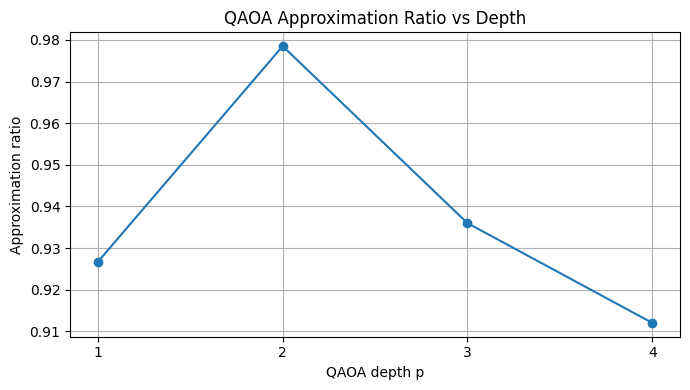

In [ ]:
all_costs = np.array([
    portfolio_cost(
        np.array([(index >> bit) & 1 for bit in range(n)], dtype=int),
        lam=LAMBDA
    )
    for index in range(2**n)
])

C_max = float(np.max(all_costs))
C_min = float(np.min(all_costs))
assert C_max > C_min

qaoa_results_df["approximation_ratio"] = (
    C_max - qaoa_results_df["expectation"]
) / (C_max - C_min)

display(qaoa_results_df[["p", "expectation", "approximation_ratio", "evaluations", "success"]])

plt.figure(figsize=(7, 4))
plt.plot(qaoa_results_df["p"], qaoa_results_df["approximation_ratio"], marker="o")
plt.xlabel("QAOA depth p")
plt.ylabel("Approximation ratio")
plt.title("QAOA Approximation Ratio vs Depth")
plt.xticks([1, 2, 3, 4])
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
evaluation_df = evaluation_df.copy()
evaluation_df["p"] = range(1, len(evaluation_df) + 1)
evaluation_df["shots"] = 4096

evaluation_df = evaluation_df[
    [
        "p",
        "shots",
        "feasible_shots",
        "feasible_rate_pct",
        "best_portfolio_hits",
        "best_hit_rate_pct",
        "best_sampled_feasible_cost"
    ]
]

evaluation_df.to_csv("qaoa_portfolio_results.csv", index=False)
display(evaluation_df.round(6))

print("Best classical portfolio (1-based):", (np.where(best_portfolio == 1)[0] + 1).tolist())
print("Classical optimum cost:", round(best_cost, 8))
print("Results saved to qaoa_portfolio_results.csv")

,p,shots,feasible_shots,feasible_rate_pct,best_portfolio_hits,best_hit_rate_pct,best_sampled_feasible_cost
0,1,4096,2564,62.597656,116,2.832031,-0.503015
1,2,4096,3927,95.874023,183,4.467773,-0.503015
2,3,4096,2985,72.875977,119,2.905273,-0.503015
3,4,4096,2282,55.712891,76,1.855469,-0.503015


Best classical portfolio (1-based): [2, 3, 6]
Classical optimum cost: -0.50301469
Results saved to qaoa_portfolio_results.csv


,lambda,feasible_shots,shots,feasible_rate_pct
0,0.1,1944,4096,47.4609
1,0.5,765,4096,18.6768
2,1.0,2673,4096,65.2588
3,2.0,1577,4096,38.5010
4,5.0,2780,4096,67.8711
5,10.0,829,4096,20.2393


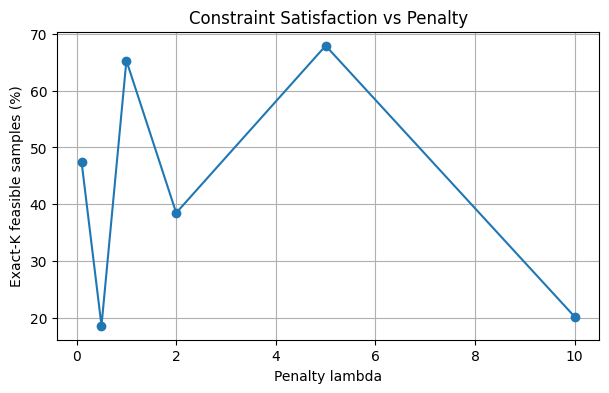

In [ ]:
penalty_results = []

for penalty in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    penalty_hamiltonian = SparsePauliOp.from_operator(
        Operator(np.diag([
            portfolio_cost(
                np.array([(index >> i) & 1 for i in range(n)], dtype=int),
                lam=penalty
            )
            for index in range(2**n)
        ]))
    ).simplify(atol=1e-12)

    penalty_ansatz = QAOAAnsatz(cost_operator=penalty_hamiltonian, reps=1, flatten=True)
    penalty_ansatz.measure_all()
    penalty_sampler = StatevectorSampler(seed=SEED + int(penalty * 100), default_shots=4096)
    initial_params = np.random.default_rng(SEED + int(penalty * 100)).uniform(0, 2 * np.pi, 2)

    def penalty_objective(params):
        circuit = penalty_ansatz.assign_parameters(params)
        counts = penalty_sampler.run([circuit], shots=4096).result()[0].data.meas.get_counts()
        total = sum(counts.values())
        return sum(
            portfolio_cost(np.array([int(bit) for bit in bits[::-1]], dtype=int), lam=penalty) * count
            for bits, count in counts.items()
        ) / total

    result = minimize(
        penalty_objective,
        initial_params,
        method="COBYLA",
        options={"maxiter": 80, "rhobeg": 0.5}
    )

    counts = penalty_sampler.run(
        [penalty_ansatz.assign_parameters(result.x)], shots=4096
    ).result()[0].data.meas.get_counts()

    feasible_count = sum(
        count for bits, count in counts.items()
        if sum(int(bit) for bit in bits) == K
    )

    penalty_results.append({
        "lambda": penalty,
        "feasible_shots": feasible_count,
        "shots": sum(counts.values()),
        "feasible_rate_pct": 100 * feasible_count / sum(counts.values())
    })

penalty_df = pd.DataFrame(penalty_results)
display(penalty_df.round(4))

plt.figure(figsize=(7, 4))
plt.plot(penalty_df["lambda"], penalty_df["feasible_rate_pct"], marker="o")
plt.xlabel("Penalty lambda")
plt.ylabel("Exact-K feasible samples (%)")
plt.title("Constraint Satisfaction vs Penalty")
plt.grid(True)
plt.show()

In [ ]:
penalty_df.to_csv("penalty_sweep_results.csv", index=False)
evaluation_df.to_csv("qaoa_portfolio_results.csv", index=False)
qaoa_results_df.to_csv("qaoa_depth_results.csv", index=False)

summary = pd.DataFrame([
    {"metric": "Number of states", "value": len(states)},
    {"metric": "Feasible portfolios", "value": len(feasible)},
    {"metric": "Classical best stocks (1-based)", "value": str((np.where(best_portfolio == 1)[0] + 1).tolist())},
    {"metric": "Classical optimum cost", "value": best_cost},
    {"metric": "Best penalty tested", "value": float(penalty_df.loc[penalty_df["feasible_rate_pct"].idxmax(), "lambda"])},
    {"metric": "Highest feasible rate (%)", "value": float(penalty_df["feasible_rate_pct"].max())},
    {"metric": "Shots per evaluation", "value": 4096}
])

summary.to_csv("portfolio_summary.csv", index=False)
display(summary)
print("Saved: penalty_sweep_results.csv, qaoa_portfolio_results.csv, qaoa_depth_results.csv, portfolio_summary.csv")

,metric,value
0,Number of states,64
1,Feasible portfolios,20
2,Classical best stocks (1-based),"[2, 3, 6]"
3,Classical optimum cost,-0.503015
4,Best penalty tested,5.0
5,Highest feasible rate (%),67.871094
6,Shots per evaluation,4096


Saved: penalty_sweep_results.csv, qaoa_portfolio_results.csv, qaoa_depth_results.csv, portfolio_summary.csv


In [ ]:
# Result packaging is intentionally performed in the final export cell at the bottom of the notebook.
# Run this notebook from top to bottom so every experiment writes its CSV before packaging.


In [ ]:
#intermediate setup
INTERMEDIATE_SEED = 2027
INTERMEDIATE_N = 12
INTERMEDIATE_K = 6
INTERMEDIATE_Q = 0.5

rng_intermediate = np.random.default_rng(INTERMEDIATE_SEED)

n_i, K_i, q_i = INTERMEDIATE_N, INTERMEDIATE_K, INTERMEDIATE_Q
mu_i = rng_intermediate.uniform(0.05, 0.25, n_i)
A_i = rng_intermediate.normal(0, 0.1, (n_i, n_i))
sigma_i = A_i @ A_i.T

states_i = np.array(list(itertools.product([0, 1], repeat=n_i)), dtype=np.int8)
feasible_i = states_i[states_i.sum(axis=1) == K_i]

def portfolio_cost_i(x, lam=1.0):
    x = np.asarray(x, dtype=float)
    return float(q_i * (x @ sigma_i @ x) - mu_i @ x + lam * (x.sum() - K_i) ** 2)

feasible_costs_i = np.array([portfolio_cost_i(x, lam=0.0) for x in feasible_i])
best_idx_i = int(np.argmin(feasible_costs_i))
best_portfolio_i = feasible_i[best_idx_i]
best_cost_i = float(feasible_costs_i[best_idx_i])

assert len(states_i) == 4096
assert len(feasible_i) == math.comb(12, 6) == 924
assert np.allclose(sigma_i, sigma_i.T)
assert np.linalg.eigvalsh(sigma_i).min() >= -1e-10

print("Intermediate states:", len(states_i))
print("Feasible portfolios:", len(feasible_i))
print("Best stocks (1-based):", (np.where(best_portfolio_i == 1)[0] + 1).tolist())
print("Classical optimum cost:", round(best_cost_i, 8))
print("INTERMEDIATE CLASSICAL BENCHMARK VERIFIED")

Intermediate states: 4096
Feasible portfolios: 924
Best stocks (1-based): [1, 4, 6, 8, 9, 12]
Classical optimum cost: -0.68721925
INTERMEDIATE CLASSICAL BENCHMARK VERIFIED


In [ ]:
INTERMEDIATE_LAMBDA = 2.0

basis_costs_i = np.zeros(2**n_i)

for index in range(2**n_i):
    x = np.array([(index >> bit) & 1 for bit in range(n_i)], dtype=int)
    basis_costs_i[index] = portfolio_cost_i(x, lam=INTERMEDIATE_LAMBDA)

hamiltonian_i = SparsePauliOp.from_operator(
    Operator(np.diag(basis_costs_i))
).simplify(atol=1e-12)

for index in range(2**n_i):
    actual = float(np.real(
        Statevector.from_int(index, dims=2**n_i).expectation_value(hamiltonian_i)
    ))
    assert np.isclose(actual, basis_costs_i[index], atol=1e-8), (index, actual, basis_costs_i[index])

print("Intermediate Hamiltonian qubits:", hamiltonian_i.num_qubits)
print("Hamiltonian terms:", len(hamiltonian_i))
print("Basis states validated:", len(basis_costs_i))
print("INTERMEDIATE HAMILTONIAN VERIFIED")

Intermediate Hamiltonian qubits: 12
Hamiltonian terms: 79
Basis states validated: 4096
INTERMEDIATE HAMILTONIAN VERIFIED


In [ ]:
P_I = 1
SHOTS_I = 4096

ansatz_i = QAOAAnsatz(cost_operator=hamiltonian_i, reps=P_I, flatten=True)
ansatz_i.measure_all()

sampler_i = StatevectorSampler(seed=INTERMEDIATE_SEED, default_shots=SHOTS_I)

def objective_i(params):
    circuit = ansatz_i.assign_parameters(params)
    counts = sampler_i.run([circuit], shots=SHOTS_I).result()[0].data.meas.get_counts()
    total = sum(counts.values())
    return sum(
        portfolio_cost_i(
            np.array([int(bit) for bit in bits[::-1]], dtype=int),
            lam=INTERMEDIATE_LAMBDA
        ) * count
        for bits, count in counts.items()
    ) / total

initial_params_i = np.random.default_rng(INTERMEDIATE_SEED).uniform(0, 2 * np.pi, 2 * P_I)

optimization_i = minimize(
    objective_i,
    initial_params_i,
    method="COBYLA",
    options={"maxiter": 100, "rhobeg": 0.5, "tol": 1e-4}
)

print("Intermediate QAOA depth:", P_I)
print("Optimization successful:", optimization_i.success)
print("Function evaluations:", optimization_i.nfev)
print("Best sampled expectation:", round(float(optimization_i.fun), 8))
print("Optimized parameters:", optimization_i.x)

Intermediate QAOA depth: 1
Optimization successful: True
Function evaluations: 26
Best sampled expectation: 1.05418877
Optimized parameters: [0.214952 3.033274]


In [ ]:
counts_i = sampler_i.run(
    [ansatz_i.assign_parameters(optimization_i.x)],
    shots=SHOTS_I
).result()[0].data.meas.get_counts()

total_i = sum(counts_i.values())
feasible_shots_i = 0
best_hits_i = 0
best_sampled_cost_i = float("inf")
best_sampled_portfolio_i = None

for bits, count in counts_i.items():
    x = np.array([int(bit) for bit in bits[::-1]], dtype=int)

    if x.sum() == K_i:
        feasible_shots_i += count
        cost = portfolio_cost_i(x, lam=0.0)

        if cost < best_sampled_cost_i:
            best_sampled_cost_i = cost
            best_sampled_portfolio_i = x.copy()

        if np.array_equal(x, best_portfolio_i):
            best_hits_i += count

intermediate_evaluation = pd.DataFrame([{
    "p": P_I,
    "shots": total_i,
    "feasible_shots": feasible_shots_i,
    "feasible_rate_pct": 100 * feasible_shots_i / total_i,
    "best_portfolio_hits": best_hits_i,
    "best_hit_rate_pct": 100 * best_hits_i / total_i,
    "best_sampled_feasible_cost": best_sampled_cost_i,
    "classical_optimum_cost": best_cost_i,
    "optimal_stocks": str((np.where(best_sampled_portfolio_i == 1)[0] + 1).tolist()) if best_sampled_portfolio_i is not None else "None"
}])

display(intermediate_evaluation.round(6))

,p,shots,feasible_shots,feasible_rate_pct,best_portfolio_hits,best_hit_rate_pct,best_sampled_feasible_cost,classical_optimum_cost,optimal_stocks
0,1,4096,2157,52.661133,1,0.024414,-0.687219,-0.687219,"[1, 4, 6, 8, 9, 12]"


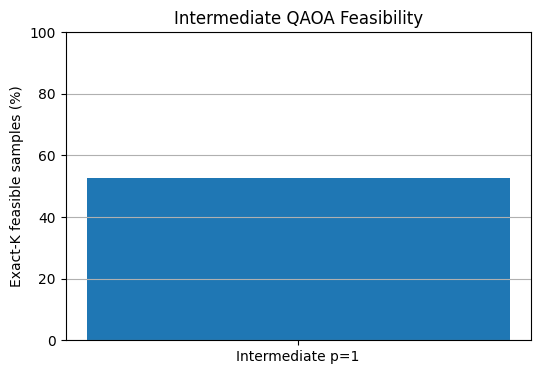

Saved: intermediate_results.csv
Classical optimum stocks: [1, 4, 6, 8, 9, 12]
Exact optimum hits: 1 out of 4096
Feasible shots: 2157 out of 4096


In [ ]:
intermediate_evaluation.to_csv("intermediate_results.csv", index=False)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Intermediate p=1"],
    intermediate_evaluation["feasible_rate_pct"],
)
plt.ylabel("Exact-K feasible samples (%)")
plt.title("Intermediate QAOA Feasibility")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

print("Saved: intermediate_results.csv")
print("Classical optimum stocks:", (np.where(best_portfolio_i == 1)[0] + 1).tolist())
print("Exact optimum hits:", best_hits_i, "out of", total_i)
print("Feasible shots:", feasible_shots_i, "out of", total_i)

### Intermediate classical baseline: simulated annealing


In [ ]:
import time

SA_SEED = 2029
SA_STEPS = 20000
SA_START_TEMP = 0.02
SA_END_TEMP = 0.0001
sa_rng = np.random.default_rng(SA_SEED)

sa_current = np.zeros(n_i, dtype=np.int8)
sa_current[sa_rng.choice(n_i, size=K_i, replace=False)] = 1
sa_current_cost = portfolio_cost_i(sa_current, lam=0.0)
sa_best = sa_current.copy()
sa_best_cost = sa_current_cost
sa_start_time = time.perf_counter()

for step in range(SA_STEPS):
    temperature = SA_START_TEMP * (SA_END_TEMP / SA_START_TEMP) ** (step / max(SA_STEPS - 1, 1))
    selected = np.flatnonzero(sa_current == 1)
    unselected = np.flatnonzero(sa_current == 0)
    candidate = sa_current.copy()
    candidate[sa_rng.choice(selected)] = 0
    candidate[sa_rng.choice(unselected)] = 1
    candidate_cost = portfolio_cost_i(candidate, lam=0.0)
    delta = candidate_cost - sa_current_cost
    if delta <= 0 or sa_rng.random() < np.exp(-delta / max(temperature, 1e-12)):
        sa_current = candidate
        sa_current_cost = candidate_cost
    if sa_current_cost < sa_best_cost:
        sa_best = sa_current.copy()
        sa_best_cost = sa_current_cost

sa_runtime_seconds = time.perf_counter() - sa_start_time
qaoa_best_feasible_cost = float(intermediate_evaluation.loc[0, "best_sampled_feasible_cost"])
classical_comparison = pd.DataFrame([
    {"method": "Exact brute force", "best_cost": best_cost_i, "gap_from_exact": 0.0, "runtime_seconds": np.nan, "notes": "Enumerates all 924 feasible portfolios; exact reference"},
    {"method": "QAOA p=1 sampled", "best_cost": qaoa_best_feasible_cost, "gap_from_exact": qaoa_best_feasible_cost - best_cost_i, "runtime_seconds": np.nan, "notes": f"{int(intermediate_evaluation.loc[0, 'shots'])} simulator shots; optimization runtime not timed"},
    {"method": "Simulated annealing", "best_cost": float(sa_best_cost), "gap_from_exact": float(sa_best_cost - best_cost_i), "runtime_seconds": sa_runtime_seconds, "notes": f"Seed {SA_SEED}; {SA_STEPS} swap proposals; feasible at every step"}
])

assert sa_best.sum() == K_i
assert np.isfinite(sa_best_cost)
classical_comparison.to_csv("intermediate_classical_comparison.csv", index=False)
display(classical_comparison.round(8))
print("Simulated annealing selected stocks (1-based):", (np.where(sa_best == 1)[0] + 1).tolist())
print("Saved: intermediate_classical_comparison.csv")


,method,best_cost,gap_from_exact,runtime_seconds,notes
0,Exact brute force,-0.687219,0.0,NaN,Enumerates all 924 feasible portfolios; exact ...
1,QAOA p=1 sampled,-0.687219,0.0,NaN,4096 simulator shots; optimization runtime not...
2,Simulated annealing,-0.687219,0.0,1.462834,Seed 2029; 20000 swap proposals; feasible at e...


Simulated annealing selected stocks (1-based): [1, 4, 6, 8, 9, 12]
Saved: intermediate_classical_comparison.csv


In [ ]:
ADVANCED_SEED = 2028
N_A = 20
K_A = 10
Q_A = 0.5
SECTOR_SIZE_A = 5
MAX_PER_SECTOR_A = 3

rng_a = np.random.default_rng(ADVANCED_SEED)
mu_a = rng_a.uniform(0.05, 0.25, N_A)
A_a = rng_a.normal(0, 0.1, (N_A, N_A))
sigma_a = A_a @ A_a.T
sectors_a = np.repeat(np.arange(4), SECTOR_SIZE_A)

def portfolio_cost_a(x):
    x = np.asarray(x, dtype=float)
    return float(Q_A * (x @ sigma_a @ x) - mu_a @ x)

best_cost_a = float("inf")
best_portfolio_a = None
feasible_count_a = 0
total_portfolios_a = math.comb(N_A, K_A)

for chosen in itertools.combinations(range(N_A), K_A):
    x = np.zeros(N_A, dtype=np.int8)
    x[list(chosen)] = 1
    sector_counts = np.bincount(sectors_a[x == 1], minlength=4)

    if np.all(sector_counts <= MAX_PER_SECTOR_A):
        feasible_count_a += 1
        cost = portfolio_cost_a(x)

        if cost < best_cost_a:
            best_cost_a = cost
            best_portfolio_a = x.copy()

assert total_portfolios_a == 184756
assert feasible_count_a > 0
assert best_portfolio_a is not None
assert best_portfolio_a.sum() == K_A
assert np.all(np.bincount(sectors_a[best_portfolio_a == 1], minlength=4) <= MAX_PER_SECTOR_A)

print("Total 10-asset portfolios:", total_portfolios_a)
print("Sector-feasible portfolios:", feasible_count_a)
print("Best stocks (1-based):", (np.where(best_portfolio_a == 1)[0] + 1).tolist())
print("Sector counts:", np.bincount(sectors_a[best_portfolio_a == 1], minlength=4).tolist())
print("Best classical cost:", round(best_cost_a, 8))
print("ADVANCED CLASSICAL BENCHMARK VERIFIED")

Total 10-asset portfolios: 184756
Sector-feasible portfolios: 80000
Best stocks (1-based): [1, 2, 5, 6, 7, 8, 12, 14, 15, 20]
Sector counts: [3, 3, 3, 1]
Best classical cost: -1.49139727
ADVANCED CLASSICAL BENCHMARK VERIFIED


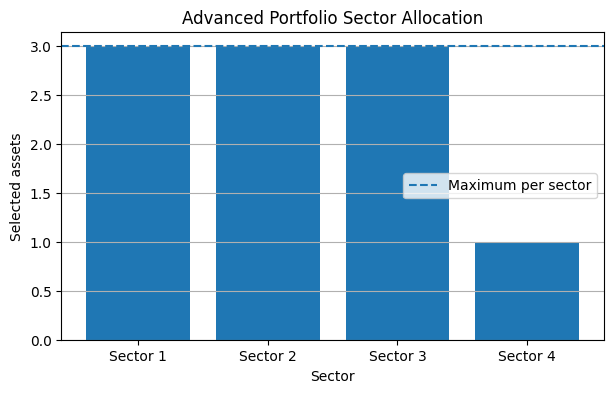

,seed,assets,selected_assets,total_portfolios,sector_feasible_portfolios,best_stocks_1_based,sector_counts,best_classical_cost,method
0,2028,20,10,184756,80000,"[1, 2, 5, 6, 7, 8, 12, 14, 15, 20]","[3, 3, 3, 1]",-1.491397,Classical exhaustive search


Saved: advanced_classical_results.csv


In [ ]:
advanced_summary = pd.DataFrame([{
    "seed": ADVANCED_SEED,
    "assets": N_A,
    "selected_assets": K_A,
    "total_portfolios": total_portfolios_a,
    "sector_feasible_portfolios": feasible_count_a,
    "best_stocks_1_based": str((np.where(best_portfolio_a == 1)[0] + 1).tolist()),
    "sector_counts": str(np.bincount(sectors_a[best_portfolio_a == 1], minlength=4).tolist()),
    "best_classical_cost": best_cost_a,
    "method": "Classical exhaustive search"
}])

advanced_summary.to_csv("advanced_classical_results.csv", index=False)

sector_counts_a = np.bincount(sectors_a[best_portfolio_a == 1], minlength=4)

plt.figure(figsize=(7, 4))
plt.bar([f"Sector {i + 1}" for i in range(4)], sector_counts_a)
plt.axhline(MAX_PER_SECTOR_A, linestyle="--", label="Maximum per sector")
plt.xlabel("Sector")
plt.ylabel("Selected assets")
plt.title("Advanced Portfolio Sector Allocation")
plt.legend()
plt.grid(axis="y")
plt.show()

display(advanced_summary)
print("Saved: advanced_classical_results.csv")

In [ ]:
assert best_portfolio_a.sum() == K_A
assert np.isclose(best_cost_a, -1.49139727, atol=1e-7)
assert feasible_count_a == 80000
assert np.all(np.bincount(sectors_a[best_portfolio_a == 1], minlength=4) <= MAX_PER_SECTOR_A)

advanced_validation = pd.DataFrame([
    {"check": "Selected exactly 10 assets", "passed": bool(best_portfolio_a.sum() == K_A)},
    {"check": "Sector cap respected", "passed": bool(np.all(np.bincount(sectors_a[best_portfolio_a == 1], minlength=4) <= MAX_PER_SECTOR_A))},
    {"check": "All 80,000 feasible portfolios checked", "passed": bool(feasible_count_a == 80000)},
    {"check": "Classical optimum reproduced", "passed": bool(np.isclose(best_cost_a, -1.49139727, atol=1e-7))}
])

display(advanced_validation)
assert advanced_validation["passed"].all()

advanced_validation.to_csv("advanced_verification_results.csv", index=False)
print("ADVANCED CLASSICAL VALIDATION PASSED")
print("Saved: advanced_verification_results.csv")

,check,passed
0,Selected exactly 10 assets,True
1,Sector cap respected,True
2,"All 80,000 feasible portfolios checked",True
3,Classical optimum reproduced,True


ADVANCED CLASSICAL VALIDATION PASSED
Saved: advanced_verification_results.csv


In [1]:
%pip install -q qiskit qiskit-ibm-runtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 12.9 MB/s eta 0:00:00


In [4]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

token = getpass("")

CJoVmVFRoZ0HaJW5YqS2nJkS-usI2lRyFzi0X0pigW7k··········


In [5]:
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token
)

print("Connected to IBM Quantum!")

qiskit_runtime_service._discover_account:WARNING:2026-10-15 02:29:32,465: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-15 02:29:46,066: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Connected to IBM Quantum!


In [6]:
for backend in service.backends(
    simulator=False,
    operational=True
):
    print(backend.name)

qiskit_runtime_service.backends:WARNING:2026-10-15 02:29:51,844: Loading instance: open-instance, plan: open


ibm_fez
ibm_kingston
ibm_marrakesh


In [7]:
backends = service.backends(
    simulator=False,
    operational=True
)

print("Operational real backends:", len(backends))

for b in backends:
    print(
        "Name:", b.name,
        "| Qubits:", b.num_qubits
    )

qiskit_runtime_service.backends:WARNING:2026-10-15 02:30:27,593: Loading instance: open-instance, plan: open


Operational real backends: 3
Name: ibm_fez | Qubits: 156
Name: ibm_kingston | Qubits: 156
Name: ibm_marrakesh | Qubits: 156


In [8]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)
isa_qc = pm.run(qc)

sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=256)

print("Backend:", backend.name)
print("Job ID:", job.job_id())
print("Status:", job.status())

result = job.result()
counts = result[0].data.meas.get_counts()

print("Counts:", counts)

qiskit_runtime_service.backends:WARNING:2026-10-15 02:30:38,033: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-15 02:30:38,665: Using instance: open-instance, plan: open
/tmp/ipykernel_672/2667877081.py:22: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Backend: ibm_marrakesh
Job ID: db83lk0r1c5c738lm3fg
Status: QUEUED
Counts: {'11': 125, '00': 126, '01': 3, '10': 2}


In [9]:
print("Final job status:", job.status())
print("Backend:", backend.name)
print("Job ID:", job.job_id())

Final job status: DONE
Backend: ibm_marrakesh
Job ID: db83lk0r1c5c738lm3fg


In [10]:

from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

print("Backend:", backend.name)
print("Available qubits:", backend.num_qubits)

assert backend.num_qubits >= 6, "Selected backend has fewer than 6 qubits."

print("Hardware is large enough for the 6-qubit problem.")
print("Next: map the notebook's actual QAOA cost Hamiltonian and parameters.")

Backend: ibm_marrakesh
Available qubits: 156
Hardware is large enough for the 6-qubit problem.
Next: map the notebook's actual QAOA cost Hamiltonian and parameters.


In [14]:
import itertools, math
import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorSampler

SEED = 2026
rng = np.random.default_rng(SEED)
n, K, q = 6, 3, 0.5
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

def portfolio_cost(x, lam=1.0):
    x = np.asarray(x, dtype=float)
    return float(q * (x @ sigma @ x) - mu @ x
                 + lam * (x.sum() - K) ** 2)

LAMBDA = 1.0
basis_costs = np.array([
    portfolio_cost(
        np.array([(idx >> i) & 1 for i in range(n)]),
        lam=LAMBDA
    )
    for idx in range(2**n)
])
hamiltonian = SparsePauliOp.from_operator(
    Operator(np.diag(basis_costs))
).simplify(atol=1e-12)

P = 1
ansatz = QAOAAnsatz(cost_operator=hamiltonian, reps=P, flatten=True)
ansatz.measure_all()
sim_sampler = StatevectorSampler(seed=SEED, default_shots=1024)

def objective(params):
    counts = sim_sampler.run(
        [ansatz.assign_parameters(params)], shots=1024
    ).result()[0].data.meas.get_counts()
    total = sum(counts.values())
    return sum(
        portfolio_cost(np.array([int(b) for b in bits[::-1]]),
                       lam=LAMBDA) * count
        for bits, count in counts.items()
    ) / total

optimization = minimize(
    objective,
    np.random.default_rng(SEED).uniform(0, 2*np.pi, 2*P),
    method="COBYLA",
    options={"maxiter": 60, "rhobeg": 1.0}
)

print("Hamiltonian qubits:", hamiltonian.num_qubits)
print("Optimizer complete:", optimization.success)
print("Optimized parameters:", optimization.x)

Hamiltonian qubits: 6
Optimizer complete: True
Optimized parameters: [4.45900238 0.3628302 ]


In [15]:
from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2
from qiskit.circuit.library import QAOAAnsatz
from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2

print("Backend:", backend.name)
assert backend.num_qubits >= 6, "Selected backend has fewer than 6 qubits."

hardware_ansatz = QAOAAnsatz(
    cost_operator=hamiltonian,
    reps=1,
    flatten=True
)
hardware_ansatz = hardware_ansatz.assign_parameters(optimization.x)
hardware_ansatz.measure_all()

hardware_circuit = transpile(
    hardware_ansatz,
    backend=backend,
    optimization_level=1
)

print("Logical qubits:", hardware_ansatz.num_qubits)
print("Hardware circuit depth:", hardware_circuit.depth())
print("Hardware operations:", hardware_circuit.count_ops())

sampler = SamplerV2(mode=backend)
job = sampler.run([hardware_circuit], shots=1024)

print("SUBMITTED JOB ID:", job.job_id())
print("Open IBM Quantum to monitor the job.")

Backend: ibm_marrakesh
Logical qubits: 6
Hardware circuit depth: 144
Hardware operations: OrderedDict({'sx': 115, 'rz': 107, 'cz': 60, 'measure': 6, 'barrier': 1})


/tmp/ipykernel_672/2459837615.py:28: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


SUBMITTED JOB ID: db83qs0r1c5c738lmabg
Open IBM Quantum to monitor the job.


In [18]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=""
)

job = service.job("db83qs0r1c5c738lmabg")
print("Status:", job.status())

qiskit_runtime_service._discover_account:WARNING:2026-10-15 02:45:25,230: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-15 02:45:27,844: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Status: DONE


In [20]:
result = job.result()
counts = result[0].data.meas.get_counts()

print("REAL IBM HARDWARE COUNTS:")
print(counts)
print("Total shots:", sum(counts.values()))

REAL IBM HARDWARE COUNTS:
{'100101': 26, '011010': 41, '110110': 20, '010101': 21, '010110': 32, '011011': 10, '001110': 44, '110001': 26, '101110': 17, '101011': 13, '011110': 13, '111100': 13, '101010': 33, '101100': 36, '101101': 15, '000100': 7, '001101': 25, '110011': 12, '100110': 37, '010001': 6, '000010': 9, '101001': 20, '011101': 21, '000110': 18, '111000': 24, '110100': 20, '001010': 20, '001011': 27, '001001': 10, '001111': 16, '011100': 35, '010100': 13, '100010': 17, '110010': 42, '000111': 22, '101000': 14, '011001': 21, '011000': 24, '010011': 20, '111001': 7, '001100': 23, '000000': 4, '110000': 14, '111110': 4, '111111': 3, '111010': 18, '010000': 3, '100001': 8, '110101': 14, '010111': 5, '011111': 3, '000101': 7, '111011': 2, '100100': 11, '100111': 9, '100011': 20, '000011': 4, '010010': 15, '110111': 2, '100000': 4, '111101': 3, '000001': 1}
Total shots: 1024


In [21]:
from collections import Counter

shots = sum(counts.values())

print("Bitstring | Count | Probability")
print("-" * 40)

for bitstring, count in sorted(
    counts.items(), key=lambda item: item[1], reverse=True
)[:10]:
    print(f"{bitstring} | {count} | {count / shots:.2%}")

print(f"\nTotal shots: {shots}")
print("Classical optimum portfolio: assets {2, 3, 6}")

Bitstring | Count | Probability
----------------------------------------
001110 | 44 | 4.30%
110010 | 42 | 4.10%
011010 | 41 | 4.00%
100110 | 37 | 3.61%
101100 | 36 | 3.52%
011100 | 35 | 3.42%
101010 | 33 | 3.22%
010110 | 32 | 3.12%
001011 | 27 | 2.64%
100101 | 26 | 2.54%

Total shots: 1024
Classical optimum portfolio: assets {2, 3, 6}


In [24]:
import numpy as np

ranked = []

for bitstring, count in counts.items():
    x = np.array([int(bit) for bit in bitstring], dtype=float)
    cost = portfolio_cost(x[::-1])
    ranked.append((bitstring, count, cost, int(x.sum())))

ranked.sort(key=lambda row: row[2])

print("Best measured portfolios:")
print("Bitstring | Count | Cost | Selected assets | Probability")

for bitstring, count, cost, selected in ranked[:10]:
    print(
        f"{bitstring} | {count} | {cost:.6f} | "
        f"{selected} | {count / sum(counts.values()):.2%}"
    )

print("\nClassical optimum cost: -0.5030146903")

Best measured portfolios:
Bitstring | Count | Cost | Selected assets | Probability
100110 | 37 | -0.503015 | 3 | 3.61%
101010 | 33 | -0.478709 | 3 | 3.22%
100011 | 20 | -0.464474 | 3 | 1.95%
110010 | 42 | -0.459651 | 3 | 4.10%
101100 | 36 | -0.422080 | 3 | 3.52%
110100 | 20 | -0.411231 | 3 | 1.95%
001110 | 44 | -0.409839 | 3 | 4.30%
100101 | 26 | -0.409479 | 3 | 2.54%
010110 | 32 | -0.407299 | 3 | 3.12%
000111 | 22 | -0.393170 | 3 | 2.15%

Classical optimum cost: -0.5030146903


## Results and limitations


## Verified real-hardware run (IBM Quantum)

The project team recorded a completed IBM Quantum Runtime execution. This section documents the saved run; retrieving it again requires the configured IBM Quantum account and is not performed by executing this notebook.

- Backend: `ibm_marrakesh`
- Job ID: `db83qs0r1c5c738lmabg`
- Final status: `DONE`
- Logical qubits: 6
- Shots: 1,024
- Transpiled circuit depth: 144
- Operations: 115 `sx`, 107 `rz`, 60 `cz`, 6 measurements, 1 barrier
- Exact classical optimum: assets `{2, 3, 6}`; cost `-0.5030146903`
- Matching measured bitstring: `100110`, 37 of 1,024 shots (3.61%)

This verifies a completed hardware run and observation of an optimal sample; it does **not** establish quantum advantage or a speedup over classical methods. Saved counts are included in the package as `ibm_marrakesh_hardware_counts.csv`.


# <b>Useful resources </b> <a id="use"></a>
### <b>QAOA and quantum optimization in Qiskit </b>
### <b>Encoding, constraints, and optimizers </b>
### <b>Hardware execution, transpilation, and error mitigation </b>
### <b>Background reading </b>


# <b>Credits and license</b>


## Advanced quantum experiment: constrained noisy-simulation pilot


In [ ]:

%pip -q install "qiskit-aer>=0.15"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 93.5 MB/s eta 0:00:00


In [ ]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit import transpile
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorSampler
from scipy.optimize import minimize
import itertools, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ADV_Q_SEED = 2030
N_Q, K_Q, SECTORS_Q, CAP_Q = 8, 4, 4, 1
Q_Q, LAMBDA_K, LAMBDA_S = 0.5, 2.0, 2.0
rng_q = np.random.default_rng(ADV_Q_SEED)
mu_q = rng_q.uniform(0.05, 0.25, N_Q)
A_q = rng_q.normal(0, 0.1, (N_Q, N_Q))
sigma_q = A_q @ A_q.T
sector_q = np.repeat(np.arange(SECTORS_Q), 2)

def pilot_cost(x):
    x = np.asarray(x, dtype=int)
    sector_counts = np.bincount(sector_q[x == 1], minlength=SECTORS_Q)
    cardinality_penalty = LAMBDA_K * (int(x.sum()) - K_Q) ** 2
    sector_penalty = LAMBDA_S * np.square(np.maximum(sector_counts - CAP_Q, 0)).sum()
    return float(Q_Q * (x @ sigma_q @ x) - mu_q @ x + cardinality_penalty + sector_penalty)

pilot_states = np.array(list(itertools.product([0, 1], repeat=N_Q)), dtype=np.int8)
pilot_feasible = np.array([
    x for x in pilot_states
    if x.sum() == K_Q and np.all(np.bincount(sector_q[x == 1], minlength=SECTORS_Q) <= CAP_Q)
], dtype=np.int8)
pilot_feasible_costs = np.array([pilot_cost(x) for x in pilot_feasible])
pilot_best = pilot_feasible[int(np.argmin(pilot_feasible_costs))]
pilot_best_cost = float(np.min(pilot_feasible_costs))

pilot_basis_costs = np.array([
    pilot_cost(np.array([(idx >> bit) & 1 for bit in range(N_Q)], dtype=int))
    for idx in range(2**N_Q)
])
pilot_hamiltonian = SparsePauliOp.from_operator(
    Operator(np.diag(pilot_basis_costs))
).simplify(atol=1e-12)
assert pilot_hamiltonian.num_qubits == N_Q
assert len(pilot_feasible) == 16
assert np.isclose(pilot_basis_costs[0], pilot_cost(np.zeros(N_Q, dtype=int)))

print("Pilot qubits:", N_Q)
print("All bitstrings:", len(pilot_states))
print("Feasible portfolios:", len(pilot_feasible))
print("Classical feasible optimum stocks (1-based):", (np.where(pilot_best == 1)[0] + 1).tolist())
print("Classical feasible optimum cost:", round(pilot_best_cost, 8))
print("Pilot Hamiltonian terms:", len(pilot_hamiltonian))


Pilot qubits: 8
All bitstrings: 256
Feasible portfolios: 16
Classical feasible optimum stocks (1-based): [2, 3, 6, 7]
Classical feasible optimum cost: -0.58989659
Pilot Hamiltonian terms: 37


In [ ]:
# Small p=1 ideal QAOA pilot. This is a simulator experiment, not hardware.
P_Q = 1
SHOTS_Q = 2048
pilot_ansatz = QAOAAnsatz(cost_operator=pilot_hamiltonian, reps=P_Q, flatten=True)
pilot_ansatz.measure_all()
pilot_sampler = StatevectorSampler(seed=ADV_Q_SEED, default_shots=SHOTS_Q)

def pilot_expectation(params):
    counts = pilot_sampler.run([pilot_ansatz.assign_parameters(params)], shots=SHOTS_Q).result()[0].data.meas.get_counts()
    return sum(
        pilot_cost(np.array([int(b) for b in bits[::-1]], dtype=int)) * count
        for bits, count in counts.items()
    ) / sum(counts.values())

pilot_initial = np.random.default_rng(ADV_Q_SEED).uniform(0, 2*np.pi, 2*P_Q)
pilot_opt = minimize(pilot_expectation, pilot_initial, method="COBYLA",
                     options={"maxiter": 35, "rhobeg": 0.8})
ideal_counts = pilot_sampler.run(
    [pilot_ansatz.assign_parameters(pilot_opt.x)], shots=SHOTS_Q
).result()[0].data.meas.get_counts()

def summarize_counts(counts, label):
    total = sum(counts.values())
    feasible_shots = 0
    best_cost_seen = float("inf")
    optimum_hits = 0
    for bitstring, count in counts.items():
        x = np.array([int(b) for b in bitstring[::-1]], dtype=int)
        sector_counts = np.bincount(sector_q[x == 1], minlength=SECTORS_Q)
        feasible = (x.sum() == K_Q and np.all(sector_counts <= CAP_Q))
        if feasible:
            feasible_shots += count
            c = Q_Q * (x @ sigma_q @ x) - mu_q @ x
            best_cost_seen = min(best_cost_seen, float(c))
            if np.array_equal(x, pilot_best):
                optimum_hits += count
    return {
        "experiment": label, "shots": total,
        "feasible_rate_pct": 100*feasible_shots/total,
        "best_feasible_cost_sampled": best_cost_seen if np.isfinite(best_cost_seen) else np.nan,
        "exact_classical_optimum_hits": optimum_hits,
        "exact_optimum_hit_rate_pct": 100*optimum_hits/total,
    }

ideal_summary = summarize_counts(ideal_counts, "Ideal statevector sampler")
print("Optimizer success:", bool(pilot_opt.success))
print("Function evaluations:", int(pilot_opt.nfev))
print("Ideal-simulation parameters:", np.round(pilot_opt.x, 6).tolist())
display(pd.DataFrame([ideal_summary]))


Optimizer success: True
Function evaluations: 30
Ideal-simulation parameters: [3.219681, 5.925408]


,experiment,shots,feasible_rate_pct,best_feasible_cost_sampled,exact_classical_optimum_hits,exact_optimum_hit_rate_pct
0,Ideal statevector sampler,2048,10.107422,-0.589897,8,0.390625


In [ ]:
# Noisy Aer simulation: depolarizing gate noise + readout assignment errors.
# The noise values are illustrative stress-test settings, not calibrated hardware data.
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.002, 1), ["u", "rx", "ry", "rz", "h", "x"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])
noise_model.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.03, 0.97]]))

aer_sim = AerSimulator(noise_model=noise_model)
# Transpile to the simulator's supported basis and inspect the circuit resource footprint.
noisy_circuit = transpile(
    pilot_ansatz.assign_parameters(pilot_opt.x),
    aer_sim,
    optimization_level=1,
    seed_transpiler=ADV_Q_SEED
)
noisy_job = aer_sim.run(noisy_circuit, shots=SHOTS_Q, seed_simulator=ADV_Q_SEED)
noisy_counts = noisy_job.result().get_counts()

noisy_summary = summarize_counts(noisy_counts, "Aer noisy simulation")
noisy_df = pd.DataFrame([ideal_summary, noisy_summary])
resource_summary = pd.DataFrame([{
    "qubits": noisy_circuit.num_qubits,
    "circuit_depth": noisy_circuit.depth(),
    "total_operations": sum(noisy_circuit.count_ops().values()),
    "operation_counts": str(dict(noisy_circuit.count_ops())),
    "noise_model": "1q depolarizing 0.002; CX depolarizing 0.01; readout assignment errors 0.02/0.03",
    "backend": "AerSimulator (simulated; not IBM hardware)"
}])

display(noisy_df)
display(resource_summary)
noisy_df.to_csv("advanced_quantum_pilot_results.csv", index=False)
resource_summary.to_csv("advanced_circuit_resources.csv", index=False)
print("Saved advanced_quantum_pilot_results.csv and advanced_circuit_resources.csv")
print("IMPORTANT: This is a noisy simulator result, not a real QPU run.")


,experiment,shots,feasible_rate_pct,best_feasible_cost_sampled,exact_classical_optimum_hits,exact_optimum_hit_rate_pct
0,Ideal statevector sampler,2048,10.107422,-0.589897,8,0.390625
1,Aer noisy simulation,2048,7.470703,-0.589897,8,0.390625


,qubits,circuit_depth,total_operations,operation_counts,noise_model,backend
0,8,42,109,"{'cx': 56, 'rz': 28, 'u': 8, 'rx': 8, 'measure...",1q depolarizing 0.002; CX depolarizing 0.01; r...,AerSimulator (simulated; not IBM hardware)


Saved advanced_quantum_pilot_results.csv and advanced_circuit_resources.csv
IMPORTANT: This is a noisy simulator result, not a real QPU run.


### Advanced experiment status and limitations


## Final export — package all results created in this run


In [ ]:
from pathlib import Path
import zipfile

required_result_files = [
    "qaoa_portfolio_results.csv",
    "qaoa_depth_results.csv",
    "penalty_sweep_results.csv",
    "portfolio_summary.csv",
    "intermediate_results.csv",
    "intermediate_classical_comparison.csv",
    "advanced_classical_results.csv",
    "advanced_verification_results.csv",
]
optional_result_files = [
    "advanced_quantum_pilot_results.csv",
    "advanced_circuit_resources.csv",
]

missing_required = [name for name in required_result_files if not Path(name).exists()]
if missing_required:
    raise FileNotFoundError(
        "Required result files are still missing: "
        f"{missing_required}. Run the corresponding experiment cells above and fix any earlier errors."
    )

export_files = required_result_files + [
    name for name in optional_result_files if Path(name).exists()
]
output_zip = "xd_clan_all_track_results.zip"
with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in export_files:
        archive.write(name)

with zipfile.ZipFile(output_zip, "r") as archive:
    assert archive.testzip() is None, "ZIP integrity check failed"
    print("Archive integrity: PASSED")
    print("Included files:")
    for name in archive.namelist():
        print(" -", name)
print("Created:", output_zip)


Archive integrity: PASSED
Included files:
 - qaoa_portfolio_results.csv
 - qaoa_depth_results.csv
 - penalty_sweep_results.csv
 - portfolio_summary.csv
 - intermediate_results.csv
 - intermediate_classical_comparison.csv
 - advanced_classical_results.csv
 - advanced_verification_results.csv
 - advanced_quantum_pilot_results.csv
 - advanced_circuit_resources.csv
Created: xd_clan_all_track_results.zip
